# 06 — Classical models and hyperparameter tuning

**Stages 9–10.** Four genuinely different model families are tuned on the final feature set:

| Model | Why it suits this problem | Weakness | Search |
|---|---|---|---|
| Logistic regression (elastic net) | Interpretable weights, well-calibrated probabilities | Linear in log-odds, misses interactions | Randomised, 40 trials |
| Decision tree (CART) | Readable if-then rules for an ops manager | Unstable and overfits without limits | Randomised, 60 trials + depth curve |
| Random forest | Averages many trees, captures interactions, robust to outliers | Larger, slower, probabilities less calibrated | Randomised, 20 trials |
| LightGBM (gradient boosting) | Usually the strongest family on tabular data | Many hyperparameters, overfits without early stopping | Optuna TPE, 100 trials, early stopping |

**Protocol.** Every trial is scored with walk-forward CV on the four training-period months (Nov 2017 → Feb 2018) using PR-AUC (average precision). The best configuration is refitted on the full matured training set and then scored on the validation period, which is used here for model comparison. The test period is still untouched.

In [1]:
import sys, time, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, psutil, joblib, optuna
import lightgbm as lgb
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import average_precision_score
from sklearn.model_selection import RandomizedSearchCV, validation_curve
from olist import config as C
from olist.baselines import MajorityBaseline, BusinessRule, core_logreg, CORE_FEATURES
from olist.evaluate import scores
from olist.features import model_features
from olist.modeling import load_task_a, task_a_sets, walk_forward_folds, make_model, tree_preprocessor, SEARCH_SPACES

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
proc = psutil.Process(); T0 = time.perf_counter()
rss = lambda: f"{proc.memory_info().rss/1e6:,.0f} MB"
def save(name): plt.savefig(C.FIGURES_DIR / f"06_{name}.png", bbox_inches="tight")
RESULTS = ROOT / "reports" / "results"; MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)

pop = load_task_a(); S = task_a_sets(pop)
TP, TRAIN, VAL = S["train_period"], S["train"], S["val"]
F = model_features()
folds = walk_forward_folds(TP)
X_tp, y_tp = TP[F], TP.late_day.astype(int)
print(f"{len(F)} features | walk-forward folds: {[len(v) for _, v in folds]} validation rows | RSS {rss()}")

42 features | walk-forward folds: [7288, 5513, 7069, 6555] validation rows | RSS 547 MB


## 1. Logistic regression, decision tree and random forest: randomised search

In [2]:
searches, search_tables = {}, {}
plan = {"logreg": (40, 20), "tree": (60, 20), "forest": (20, 5)}       # (trials, parallel jobs)
for name, (n_iter, n_jobs) in plan.items():
    t = time.perf_counter()
    rs = RandomizedSearchCV(make_model(name, F), SEARCH_SPACES[name], n_iter=n_iter, cv=folds, scoring="average_precision",
                            n_jobs=n_jobs, random_state=C.SEED, refit=False, error_score="raise")
    rs.fit(X_tp, y_tp)
    searches[name] = rs
    tab = pd.DataFrame(rs.cv_results_)
    keep = [c for c in tab.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score", "mean_fit_time"]
    search_tables[name] = tab[keep].sort_values("rank_test_score")
    search_tables[name].to_csv(RESULTS / f"06_search_{name}.csv", index=False)
    print(f"{name:7s} {n_iter} trials x {len(folds)} folds in {time.perf_counter()-t:5.0f}s | best CV PR-AUC "
          f"{rs.best_score_:.4f} ± {tab.std_test_score[rs.best_index_]:.4f} | {rs.best_params_}")

logreg  40 trials x 4 folds in   150s | best CV PR-AUC 0.1825 ± 0.0803 | {'clf__C': np.float64(0.002999511852989261), 'clf__class_weight': None, 'clf__l1_ratio': np.float64(0.3109823217156622)}


tree    60 trials x 4 folds in    14s | best CV PR-AUC 0.1380 ± 0.0387 | {'clf__ccp_alpha': np.float64(0.0005577427051843638), 'clf__class_weight': None, 'clf__criterion': 'entropy', 'clf__max_depth': 18, 'clf__min_samples_leaf': 150, 'clf__min_samples_split': 149}


forest  20 trials x 4 folds in   395s | best CV PR-AUC 0.1489 ± 0.0587 | {'clf__class_weight': None, 'clf__max_depth': 18, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 19, 'clf__n_estimators': 306}


### Decision-tree depth: watching overfitting happen

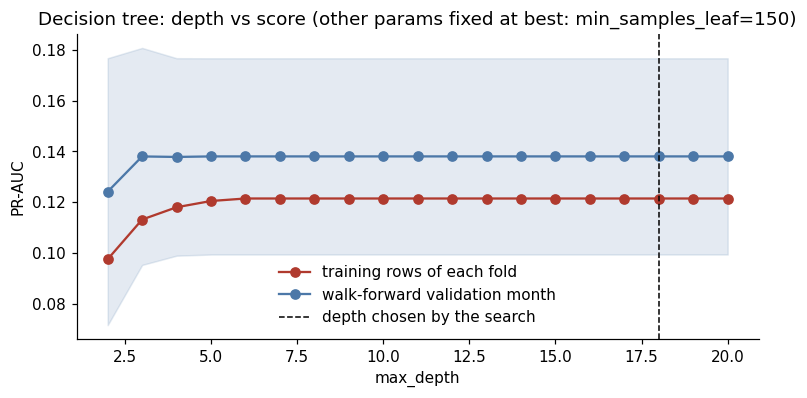

depth,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
train,0.098,0.113,0.118,0.120,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121,0.121
cv,0.124,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138,0.138


In [3]:
bt = {k.replace("clf__", ""): v for k, v in searches["tree"].best_params_.items() if k != "clf__max_depth"}
depths = np.arange(2, 21)
tr_s, cv_s = validation_curve(make_model("tree", F, **bt), X_tp, y_tp, param_name="clf__max_depth", param_range=depths,
                              cv=folds, scoring="average_precision", n_jobs=19)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(depths, tr_s.mean(1), marker="o", label="training rows of each fold", color="#B03A2E")
ax.plot(depths, cv_s.mean(1), marker="o", label="walk-forward validation month", color="#4C78A8")
ax.fill_between(depths, cv_s.mean(1) - cv_s.std(1), cv_s.mean(1) + cv_s.std(1), color="#4C78A8", alpha=0.15)
ax.axvline(searches["tree"].best_params_["clf__max_depth"], color="k", ls="--", lw=1, label="depth chosen by the search")
ax.set_xlabel("max_depth"); ax.set_ylabel("PR-AUC"); ax.legend(frameon=False); ax.set_title(f"Decision tree: depth vs score (other params fixed at best: min_samples_leaf={bt['min_samples_leaf']})")
save("tree_depth_curve"); plt.show()
pd.DataFrame({"depth": depths, "train": tr_s.mean(1), "cv": cv_s.mean(1)}).set_index("depth").T.round(3)

## 2. LightGBM with Optuna (Bayesian TPE search, early stopping on an inner holdout)

For each walk-forward fold, the **last 15% of the fold's training rows (by purchase time)** are held out as an early-stopping set. The booster trains up to 3,000 trees and stops when the *log-loss* on that inner holdout has not improved for 150 rounds. The validation month is then scored at that tree count. The preprocessing is fitted once per fold on the remaining 85% and cached; only the booster changes between trials. The final model uses the median best tree count of the best trial.

`scale_pos_weight` is fixed at 1, following the Stage 6 decision to train on the natural class ratio. This also keeps the early-stopping signal meaningful. An intermediate version let the search upweight late orders (it chose 4.7); that shifts the probabilities on purpose, so the holdout log-loss worsened from the first tree and the search settled on a 2-tree model.

> **Lesson learned, kept on purpose.** A first version of this search stopped early on the *scored validation month itself*, using PR-AUC. On noisy months it stopped after as few as 1–12 trees, and the median best tree count of the winning trial was **10**. That produced an optimistic CV score (0.186) and an almost untrained final model (validation PR-AUC 0.181, worse than the untuned LightGBM in notebook 05). Stopping on a separate inner holdout with a smooth loss removes both problems: the month being scored no longer influences how many trees are grown.

In [4]:
fold_data = []
for tr, va in folds:
    cut = int(len(tr) * 0.85)                       # rows are sorted by purchase time
    fit_idx, es_idx = tr[:cut], tr[cut:]
    pre = tree_preprocessor(F).fit(X_tp.iloc[fit_idx], y_tp.iloc[fit_idx])
    fold_data.append((pre.transform(X_tp.iloc[fit_idx]), y_tp.iloc[fit_idx].to_numpy(),
                      pre.transform(X_tp.iloc[es_idx]), y_tp.iloc[es_idx].to_numpy(),
                      pre.transform(X_tp.iloc[va]), y_tp.iloc[va].to_numpy()))
ratio = (y_tp == 0).sum() / (y_tp == 1).sum()

def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 8, 255, log=True),
        max_depth=trial.suggest_categorical("max_depth", [-1, 4, 6, 8, 10]),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 500, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
    )
    aps, iters = [], []
    for Xtr, ytr, Xes, yes, Xva, yva in fold_data:
        m = lgb.LGBMClassifier(n_estimators=3000, random_state=C.SEED, n_jobs=5, verbose=-1, metric="binary_logloss", **params)
        m.fit(Xtr, ytr, eval_set=[(Xes, yes)], callbacks=[lgb.early_stopping(150, verbose=False)])
        aps.append(average_precision_score(yva, m.predict_proba(Xva)[:, 1])); iters.append(m.best_iteration_ or 3000)
    trial.set_user_attr("fold_scores", aps); trial.set_user_attr("best_iters", iters)
    return float(np.mean(aps))

t = time.perf_counter()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=C.SEED))
study.optimize(objective, n_trials=100, n_jobs=4)
lgb_tab = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs")).sort_values("value", ascending=False)
lgb_tab.to_csv(RESULTS / "06_search_lgbm.csv", index=False)
best = study.best_trial
lgb_best = {**best.params, "subsample_freq": 1, "n_estimators": int(np.median(best.user_attrs["best_iters"]))}
print(f"100 trials in {time.perf_counter()-t:.0f}s | best CV PR-AUC {best.value:.4f} ± {np.std(best.user_attrs['fold_scores']):.4f}")
print("best params:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in lgb_best.items()})

100 trials in 107s | best CV PR-AUC 0.1565 ± 0.0680
best params: {'learning_rate': 0.0195, 'num_leaves': 56, 'max_depth': 8, 'min_child_samples': 14, 'subsample': 0.6709, 'colsample_bytree': 0.4092, 'reg_lambda': 1.8031, 'reg_alpha': 0.004, 'subsample_freq': 1, 'n_estimators': 120}


## 3. Score versus trial

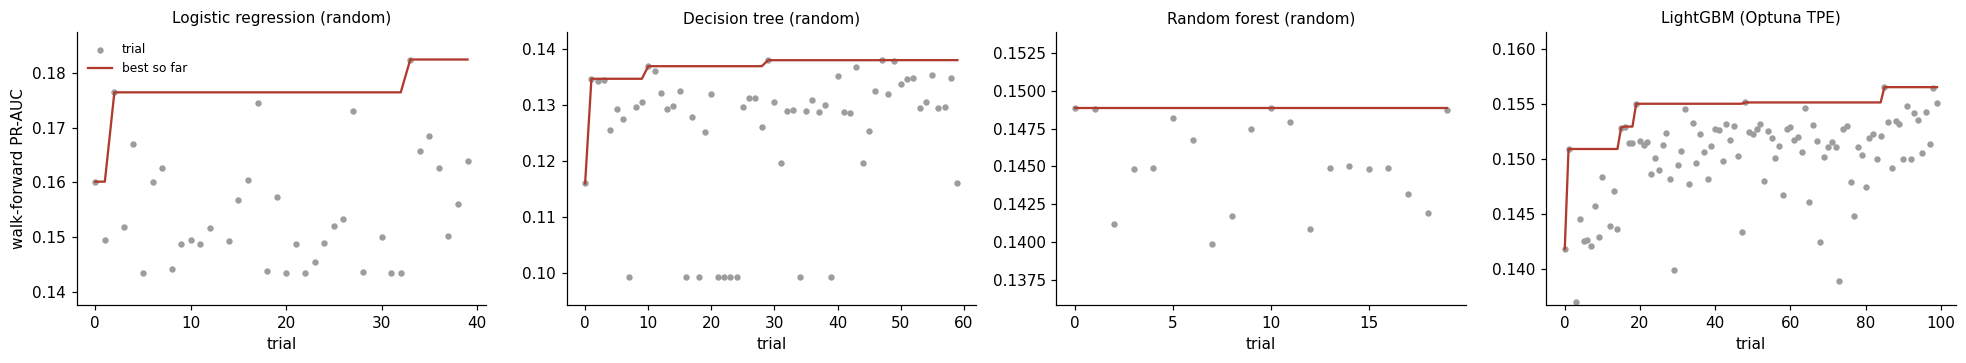

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
traces = {n: search_tables[n].sort_index()["mean_test_score"].to_numpy() for n in ["logreg", "tree", "forest"]}
traces["lgbm"] = np.array([t.value for t in study.trials])
titles = {"logreg": "Logistic regression (random)", "tree": "Decision tree (random)", "forest": "Random forest (random)", "lgbm": "LightGBM (Optuna TPE)"}
for ax, (n, v) in zip(axes, traces.items()):
    ax.scatter(np.arange(len(v)), v, s=10, color="#9D9D9D", label="trial")
    ax.plot(np.maximum.accumulate(v), color="#B03A2E", label="best so far")
    ax.set_title(titles[n], fontsize=10); ax.set_xlabel("trial"); ax.set_ylim(np.percentile(v, 5) - 0.005, v.max() + 0.005)
axes[0].set_ylabel("walk-forward PR-AUC"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); save("score_vs_trial"); plt.show()

## 4. Refit the best configurations and compare train, CV and validation

In [6]:
best_params = {n: {k.replace("clf__", ""): v for k, v in searches[n].best_params_.items()} for n in ["logreg", "tree", "forest"]}
best_params["lgbm"] = lgb_best
cv_summary = {n: (searches[n].best_score_, pd.DataFrame(searches[n].cv_results_).std_test_score[searches[n].best_index_]) for n in ["logreg", "tree", "forest"]}
cv_summary["lgbm"] = (best.value, float(np.std(best.user_attrs["fold_scores"])))
final_models = {}
rows = []
for n in ["logreg", "tree", "forest", "lgbm"]:
    t = time.perf_counter()
    params = dict(best_params[n])
    if n == "lgbm":
        params["n_jobs"] = 8
    m = make_model(n, F, **params).fit(TRAIN[F], TRAIN.late_day)
    final_models[n] = m
    joblib.dump(m, MODELS / f"task_a_{n}.joblib")
    p_tr, p_va = m.predict_proba(TRAIN[F])[:, 1], m.predict_proba(VAL[F])[:, 1]
    s_tr, s_va = scores(TRAIN.late_day, p_tr), scores(VAL.late_day, p_va)
    rows.append({"model": n, "train_pr_auc": s_tr["pr_auc"], "cv_pr_auc": cv_summary[n][0], "cv_sd": cv_summary[n][1],
                 "val_pr_auc": s_va["pr_auc"], "val_roc_auc": s_va["roc_auc"], "val_brier": s_va["brier"],
                 "train_minus_cv": s_tr["pr_auc"] - cv_summary[n][0], "fit_s": time.perf_counter() - t})
# baselines refitted the same way for the comparison
for n, est, feats in [("baseline: majority", MajorityBaseline(), F), ("baseline: business rule", BusinessRule(), F),
                      ("baseline: core logreg", core_logreg(), CORE_FEATURES)]:
    est.fit(TRAIN[feats], TRAIN.late_day); joblib.dump(est, MODELS / f"task_a_{n.split(': ')[1].replace(' ', '_')}.joblib")
    rows.append({"model": n, "train_pr_auc": scores(TRAIN.late_day, est.predict_proba(TRAIN[feats])[:, 1])["pr_auc"],
                 "val_pr_auc": scores(VAL.late_day, est.predict_proba(VAL[feats])[:, 1])["pr_auc"],
                 "val_roc_auc": scores(VAL.late_day, est.predict_proba(VAL[feats])[:, 1])["roc_auc"]})
comp = pd.DataFrame(rows).set_index("model")
comp.to_csv(RESULTS / "06_model_comparison.csv")
json.dump({k: {kk: (vv if not isinstance(vv, np.generic) else vv.item()) for kk, vv in v.items()} for k, v in best_params.items()},
          open(RESULTS / "06_best_params.json", "w"), indent=2, default=str)
json.dump(F, open(MODELS / "task_a_features.json", "w"), indent=1)
comp.round(4)

,train_pr_auc,cv_pr_auc,cv_sd,val_pr_auc,val_roc_auc,val_brier,train_minus_cv,fit_s
model,,,,,,,,
logreg,0.1579,0.1825,0.0803,0.2213,0.6693,0.1027,-0.0246,0.8321
tree,0.1714,0.1380,0.0387,0.1611,0.6111,0.1084,0.0334,0.9325
forest,0.4845,0.1489,0.0587,0.2009,0.6348,0.1034,0.3357,8.2757
lgbm,0.3652,0.1565,0.0680,0.2168,0.6494,0.1045,0.2087,0.5891
baseline: majority,0.0564,NaN,NaN,0.1184,0.5000,NaN,NaN,NaN
baseline: business rule,0.0647,NaN,NaN,0.1245,0.5262,NaN,NaN,NaN
baseline: core logreg,0.1238,NaN,NaN,0.1384,0.5513,NaN,NaN,NaN


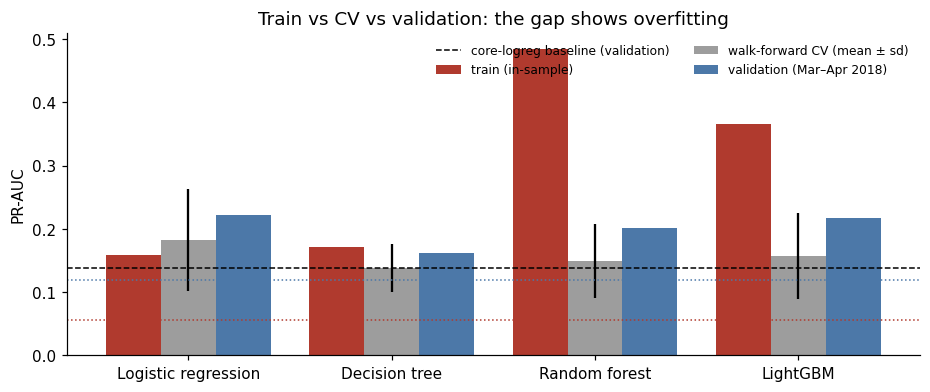

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.8))
m4 = comp.loc[["logreg", "tree", "forest", "lgbm"]]
x = np.arange(len(m4))
ax.bar(x - 0.27, m4.train_pr_auc, 0.27, label="train (in-sample)", color="#B03A2E")
ax.bar(x, m4.cv_pr_auc, 0.27, yerr=m4.cv_sd, label="walk-forward CV (mean ± sd)", color="#9D9D9D")
ax.bar(x + 0.27, m4.val_pr_auc, 0.27, label="validation (Mar–Apr 2018)", color="#4C78A8")
for lvl, nm, c in [(TRAIN.late_day.mean(), "train base rate", "#B03A2E"), (VAL.late_day.mean(), "validation base rate", "#4C78A8")]:
    ax.axhline(lvl, ls=":", color=c, lw=1)
ax.axhline(comp.loc["baseline: core logreg", "val_pr_auc"], ls="--", color="k", lw=1, label="core-logreg baseline (validation)")
ax.set_xticks(x, ["Logistic regression", "Decision tree", "Random forest", "LightGBM"]); ax.set_ylabel("PR-AUC")
ax.legend(frameon=False, fontsize=8, ncol=2); ax.set_title("Train vs CV vs validation: the gap shows overfitting")
save("train_cv_val"); plt.show()

**Findings.**
* **Regularised logistic regression wins.** Its best walk-forward PR-AUC is 0.183 ± 0.080 (C ≈ 0.003, elastic-net `l1_ratio` 0.31, no class weights), up from 0.152 with default settings (notebook 04). Validation PR-AUC is **0.221**. Heavy regularisation is what helps: when a weak signal is spread over many correlated features, shrinking the weights stops the model chasing noise. Its training PR-AUC (0.158) is *below* its CV score only because the training set's base rate (5.6%) is lower than the folds' average. PR-AUC must always be read against the base rate of the period it was measured on.
* **LightGBM** (120 trees, learning rate 0.02, 56 leaves) reaches validation 0.217, close to logistic regression. Its CV score is lower (0.157), and its train–CV gap (0.21) shows it fits patterns the linear model ignores.
* **Random forest** overfits the most: training 0.485 against CV 0.149, with validation 0.201.
* **The decision tree** plateaus from depth 3–5. With `min_samples_leaf` = 150 and cost-complexity pruning (`ccp_alpha` ≈ 0.0006), deeper trees are pruned back to the same small tree, so both curves flatten (training about 0.12, CV about 0.14). Its validation PR-AUC (0.161) is the weakest of the four but still above every baseline.
* **Every tuned model beats all three baselines on validation**; the best baseline, the core logistic regression, scores 0.138.
* **No search chose class weighting.** All four best configurations train on the natural class ratio, consistent with Stage 6.

**Decision.** Logistic regression has the best validation PR-AUC, so it becomes the primary model for evaluation (notebook 07) and for decisions (notebook 08). LightGBM is kept as the strongest non-linear challenger and is used for the SHAP explanations. Validation chose the model; this notebook never touches the test period.

In [8]:
print(f"notebook runtime {time.perf_counter()-T0:.1f}s | final RSS {rss()}")

notebook runtime 694.1s | final RSS 724 MB
